# Survey validation: DESI, Rubin/LSST, SKAO and Planck

This notebook is a quick companion to `docs/source/survey_validation.md`. It runs a small
subset of the survey forecast comparison (Euclid 3x2pt, Rubin/LSST 3x2pt and DESI ELG
galaxy clustering), checks the observable-level validation, and shows the figures produced
by `scripts/validation/plot_survey_validation.py`.

Everything here uses the GR fiducial and the `symbolic` backend. The full comparison,
including SKAO and Planck and the w0waCDM run, takes a few minutes and is reproduced with
the three commands in the documentation page.

## Setup

In [1]:
import json
import subprocess
import sys
import tempfile
from pathlib import Path

import matplotlib.pyplot as plt
import pandas as pd
from IPython.display import Image, display

REPO_ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
WORKDIR = Path(tempfile.mkdtemp(prefix="survey_validation_"))
print("Working directory:", WORKDIR)

Working directory: /tmp/survey_validation_yr3tq_4z


## Quick forecast run

Three cases are enough to see the pipeline in action: two photometric surveys with the
same 3x2pt probe combination, and one spectroscopic survey. The script writes a JSON
summary and the Fisher matrices into the working directory.

In [2]:
cases = ["euclid-photo", "rubin-photo", "desi-elg"]
command = [
    sys.executable,
    str(REPO_ROOT / "scripts/validation/run_survey_forecasts.py"),
    "--model",
    "LCDM",
    "--output-dir",
    str(WORKDIR),
]
for case in cases:
    command.extend(["--case", case])
subprocess.run(command, check=True, cwd=REPO_ROOT)


Running Euclid photometric (GCph+WL) ...



  Fisher matrix exported: /tmp/survey_validation_yr3tq_4z/fishers/CosmicFish_v2.0.0_survey_forecast_lcdm_euclid_photo_GCphWL_FM.txt

Running Rubin/LSST photometric (GCph+WL) ...



  Fisher matrix exported: /tmp/survey_validation_yr3tq_4z/fishers/CosmicFish_v2.0.0_survey_forecast_lcdm_rubin_photo_GCphWL_FM.txt

Running DESI ELG (GCsp) ...


Computing derivatives of Galaxy Clustering Spectro
>> Computing Derivs >>

  Fisher matrix exported: /tmp/survey_validation_yr3tq_4z/fishers/CosmicFish_v2.0.0_survey_forecast_lcdm_desi_elg_GCsp_FM.txt


| Case | Omegam | Omegab | h | ns | sigma8 | Time (s) |
| --- | --- | --- | --- | --- | --- | --- |
| Euclid photometric (GCph+WL) | 0.002414 | 0.002182 | 0.01733 | 0.009728 | 0.002995 | 8.3 |
| Rubin/LSST photometric (GCph+WL) | 0.00125 | 0.00199 | 0.01185 | 0.004996 | 0.001591 | 7.8 |
| DESI ELG (GCsp) | 0.005035 | 0.001454 | 0.008439 | 0.009342 | 0.005353 | 11.5 |

Wrote /tmp/survey_validation_yr3tq_4z/survey_forecasts_LCDM.json
Wrote /tmp/survey_validation_yr3tq_4z/survey_forecasts_LCDM.md


CompletedProcess(args=['/home/santiago/CosmoProjects/cosmicfish_release/cosmicjellyfish/.venv/bin/python', '/home/santiago/CosmoProjects/cosmicfish_release/cosmicjellyfish/scripts/validation/run_survey_forecasts.py', '--model', 'LCDM', '--output-dir', '/tmp/survey_validation_yr3tq_4z', '--case', 'euclid-photo', '--case', 'rubin-photo', '--case', 'desi-elg'], returncode=0)

The JSON summary is easy to turn into a table of marginalised errors.

In [3]:
report = json.loads((WORKDIR / "survey_forecasts_LCDM.json").read_text())
rows = [
    {"survey": result["label"], **result["sigma"], "time [s]": round(result["elapsed_s"], 1)}
    for result in report["results"]
]
pd.DataFrame(rows).set_index("survey").style.format(precision=4)

,Omegam,Omegab,h,ns,sigma8,time [s]
survey,,,,,,
Euclid photometric (GCph+WL),0.0024,0.0022,0.0173,0.0097,0.0030,8.3000
Rubin/LSST photometric (GCph+WL),0.0012,0.0020,0.0118,0.0050,0.0016,7.8000
DESI ELG (GCsp),0.0050,0.0015,0.0084,0.0093,0.0054,11.5000


## Observable validation

The validation harness compares the package observables with an independent transcription
of the historical recipes. It needs a local checkout of the SKAO forecast project; if that
is not available, the script reports the missing path instead of failing silently.

In [4]:
result = subprocess.run(
    [
        sys.executable,
        str(REPO_ROOT / "scripts/validation/validate_survey_observables.py"),
        "--output-dir",
        str(WORKDIR),
    ],
    cwd=REPO_ROOT,
)
if result.returncode != 0:
    raise RuntimeError(
        "Observable validation failed. Set COSMICFISH_HISTORICAL_DIR to a checkout "
        "that contains survey_specifications/ and data-for-fig1.dat."
    )


Validating desi-bgs (DESI, gcsp) ...
Validating desi-elg (DESI, gcsp) ...
Validating skao-hi (SKAO, gcsp) ...
Validating skao-im (SKAO, im) ...
Validating skao-im-desi (SKAO, im-cross) ...
Validating rubin-photo (Rubin, photo) ...
Validating skao-photo (SKAO, photo) ...
Validating fig1 (SKAO, fig1) ...
Wrote /tmp/survey_validation_yr3tq_4z/fig1_diagnostic.json

survey         observable     quantity                    max rel. diff  status
-------------------------------------------------------------------------------
desi-bgs       GCsp           n_density [Mpc^-3]              0.000e+00  ok
desi-bgs       GCsp           volume_survey [Mpc^3]           2.014e-16  ok
desi-bgs       GCsp           fiducial bias                   0.000e+00  ok
desi-bgs       GCsp           P_gg(k, mu, z)                  5.226e-16  ok
desi-elg       GCsp           n_density [Mpc^-3]              1.222e-16  ok
desi-elg       GCsp           volume_survey [Mpc^3]           2.410e-16  ok
desi-elg       GCsp 

In [5]:
rows_path = WORKDIR / "observable_validation.json"
if not rows_path.exists():
    raise FileNotFoundError(
        "observable_validation.json was not written; check the validation run above."
    )
report = json.loads(rows_path.read_text())
frame = pd.DataFrame(report["rows"])
failed = frame[frame["status"] == "check"]
if len(failed):
    raise RuntimeError(f"{len(failed)} observable checks failed:\n{failed.to_string()}")
print(frame["status"].value_counts())
frame.head(12)


status
ok          39
expected     8
Name: count, dtype: int64


,survey,observable,quantity,max_relative_difference,status,note
0,desi-bgs,GCsp,n_density [Mpc^-3],0.000000e+00,ok,
1,desi-bgs,GCsp,volume_survey [Mpc^3],2.013651e-16,ok,
2,desi-bgs,GCsp,fiducial bias,0.000000e+00,ok,
3,desi-bgs,GCsp,"P_gg(k, mu, z)",5.225741e-16,ok,s8-normalised paper form
4,desi-elg,GCsp,n_density [Mpc^-3],1.222200e-16,ok,
5,desi-elg,GCsp,volume_survey [Mpc^3],2.409968e-16,ok,
6,desi-elg,GCsp,fiducial bias,0.000000e+00,ok,
7,desi-elg,GCsp,"P_gg(k, mu, z)",6.647433e-16,ok,s8-normalised paper form
8,skao-hi,GCsp,n_density [Mpc^-3],2.158285e-16,ok,
9,skao-hi,GCsp,volume_survey [Mpc^3],1.409556e-16,ok,


## Survey inputs

The left panel shows the spectroscopic and intensity-mapping number densities; the right
panel shows the analytic photometric `dN/dz` of the three imaging surveys. Both are read
straight from the shipped YAML files, so the figure also documents the migrated
specifications.

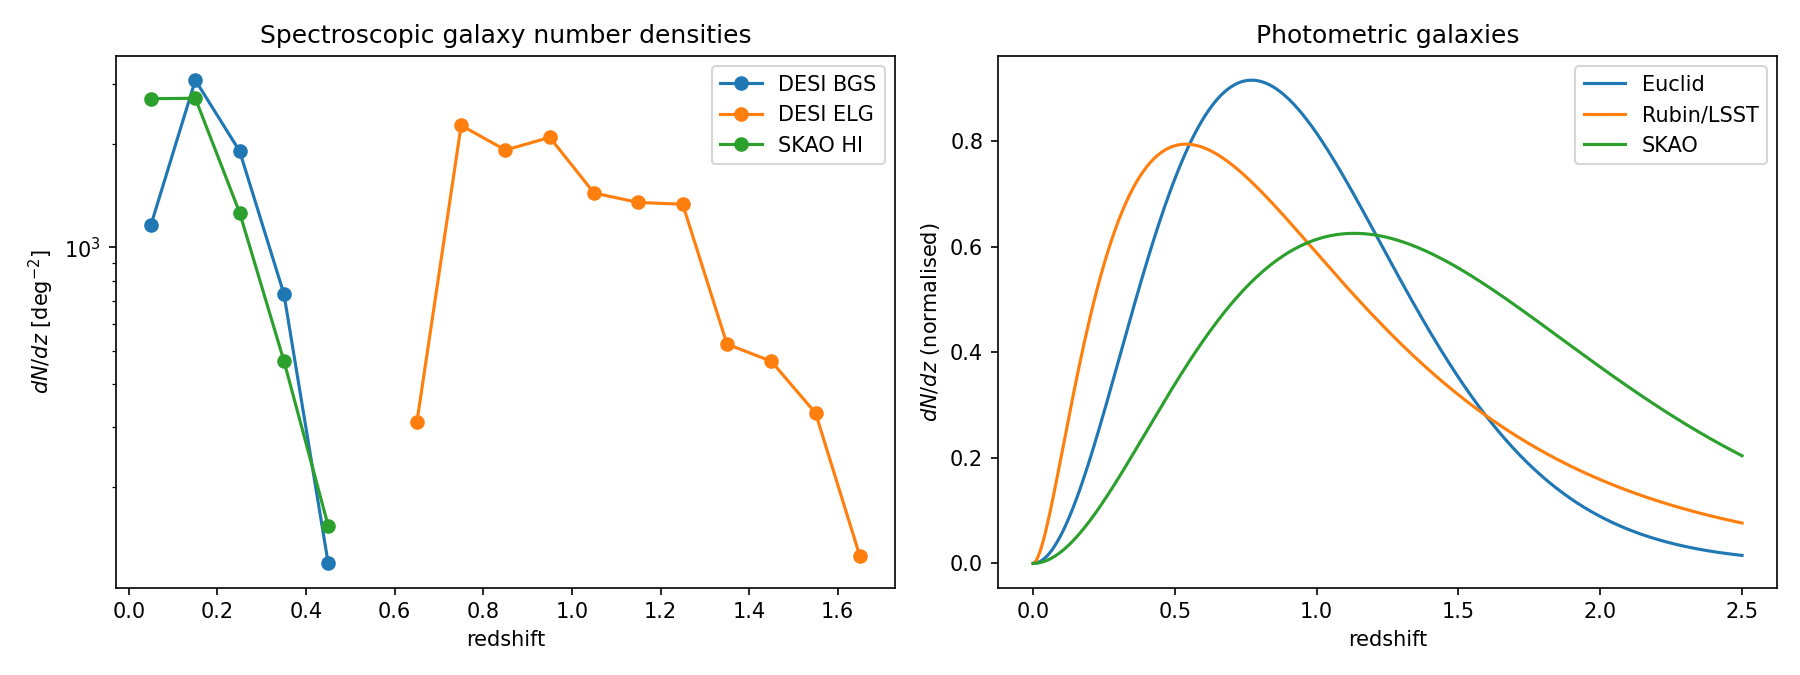

In [6]:
sys.path.insert(0, str(REPO_ROOT / "scripts/validation"))
import plot_survey_validation as plots

figure_path = plots.plot_survey_inputs(WORKDIR)
display(Image(filename=str(figure_path)))

## Full comparison figures

These are the figures committed with the documentation. They come from the complete LCDM
and w0waCDM runs, not from the quick subset above.

forecast_errors.png


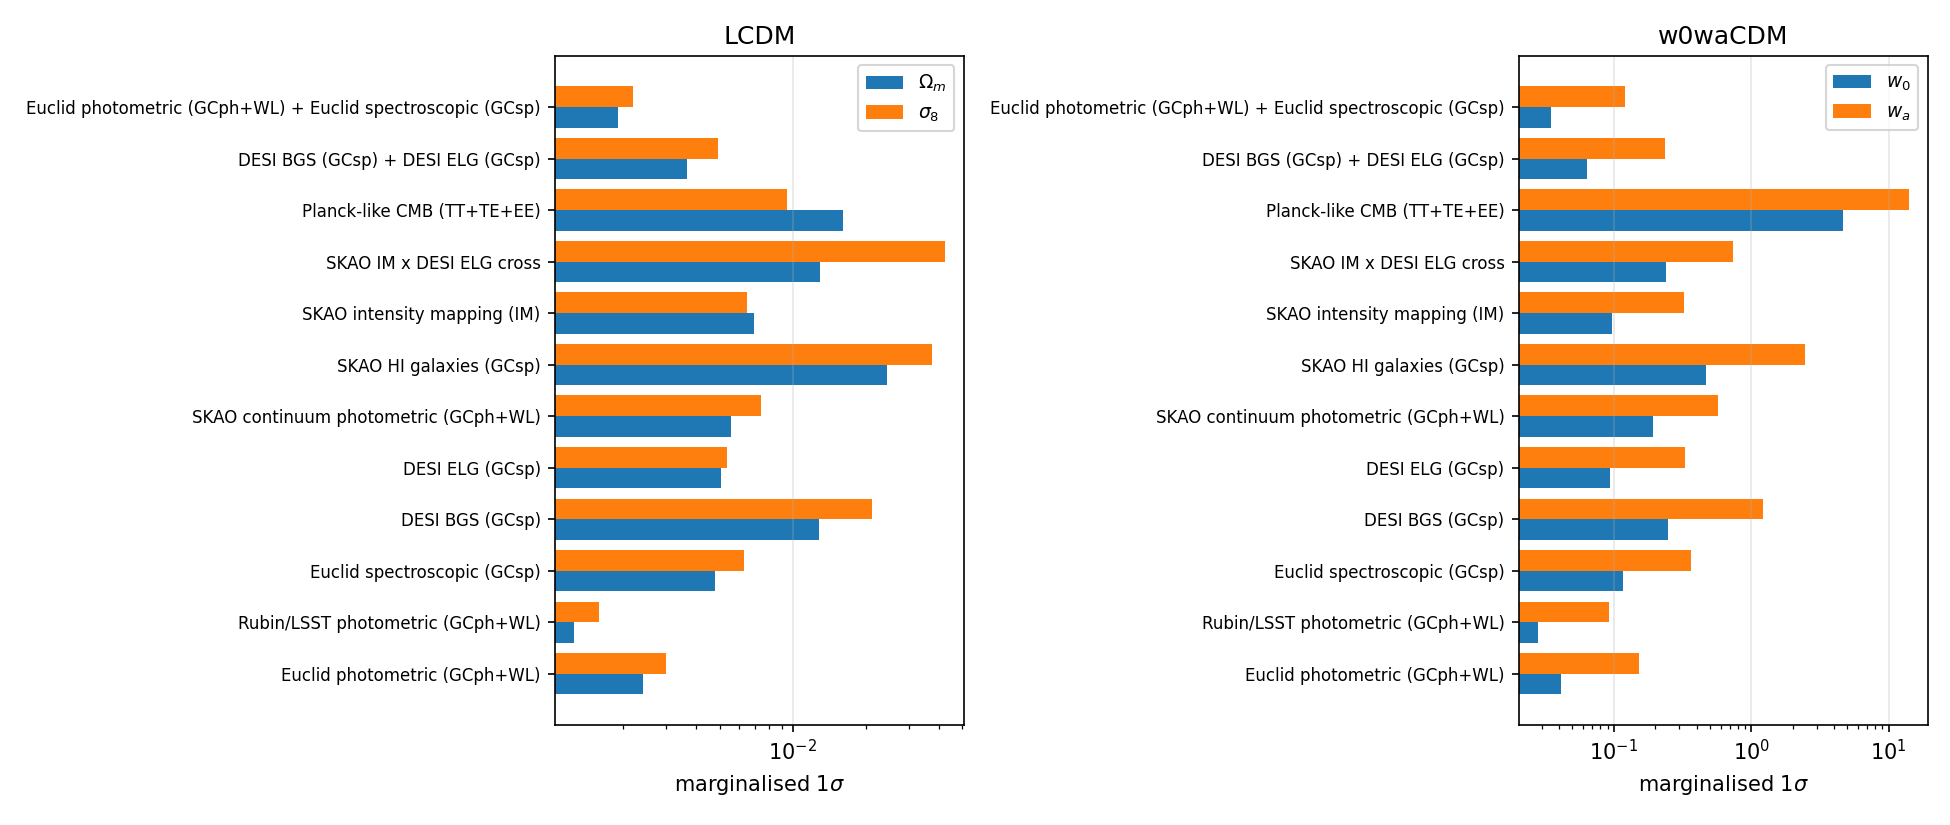

w0wa_comparisons.png


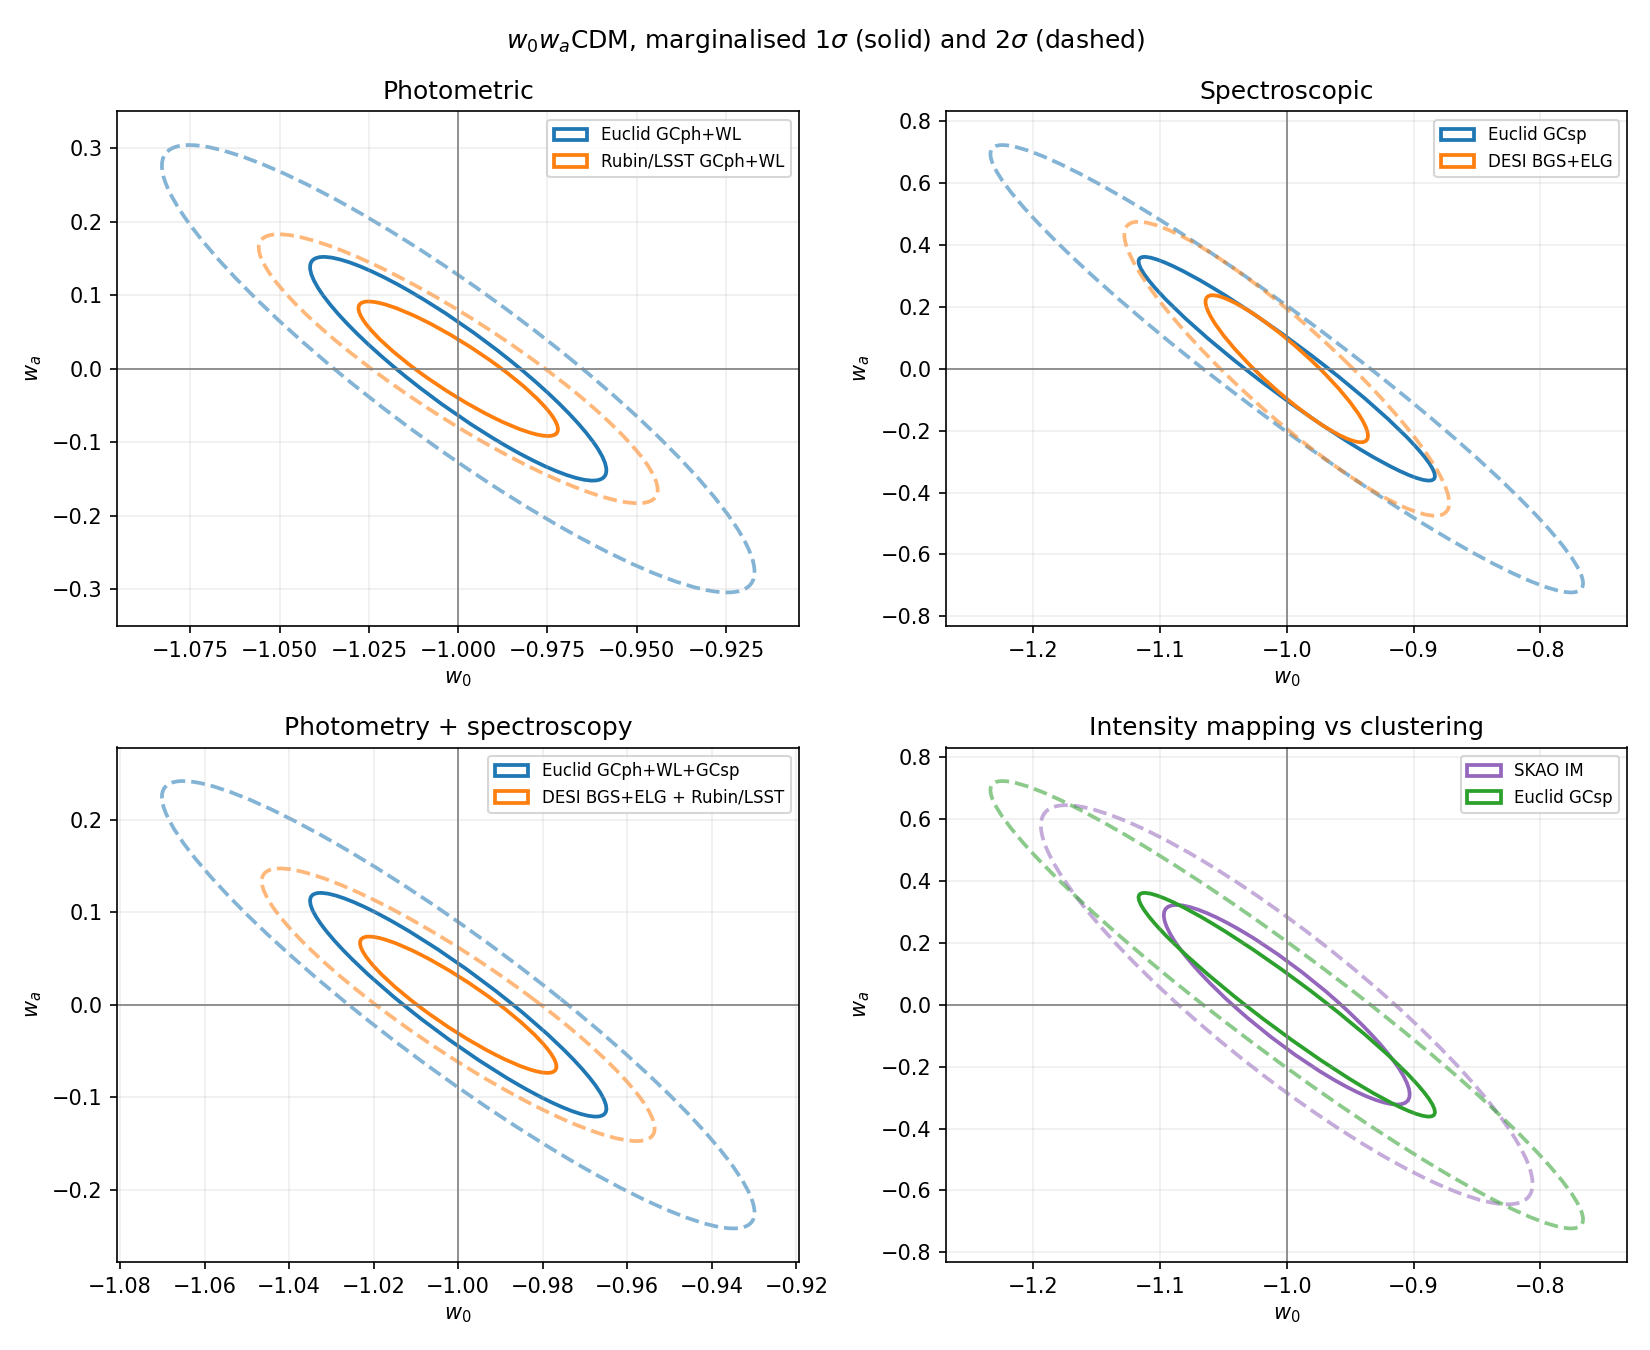

fig1_diagnostic.png


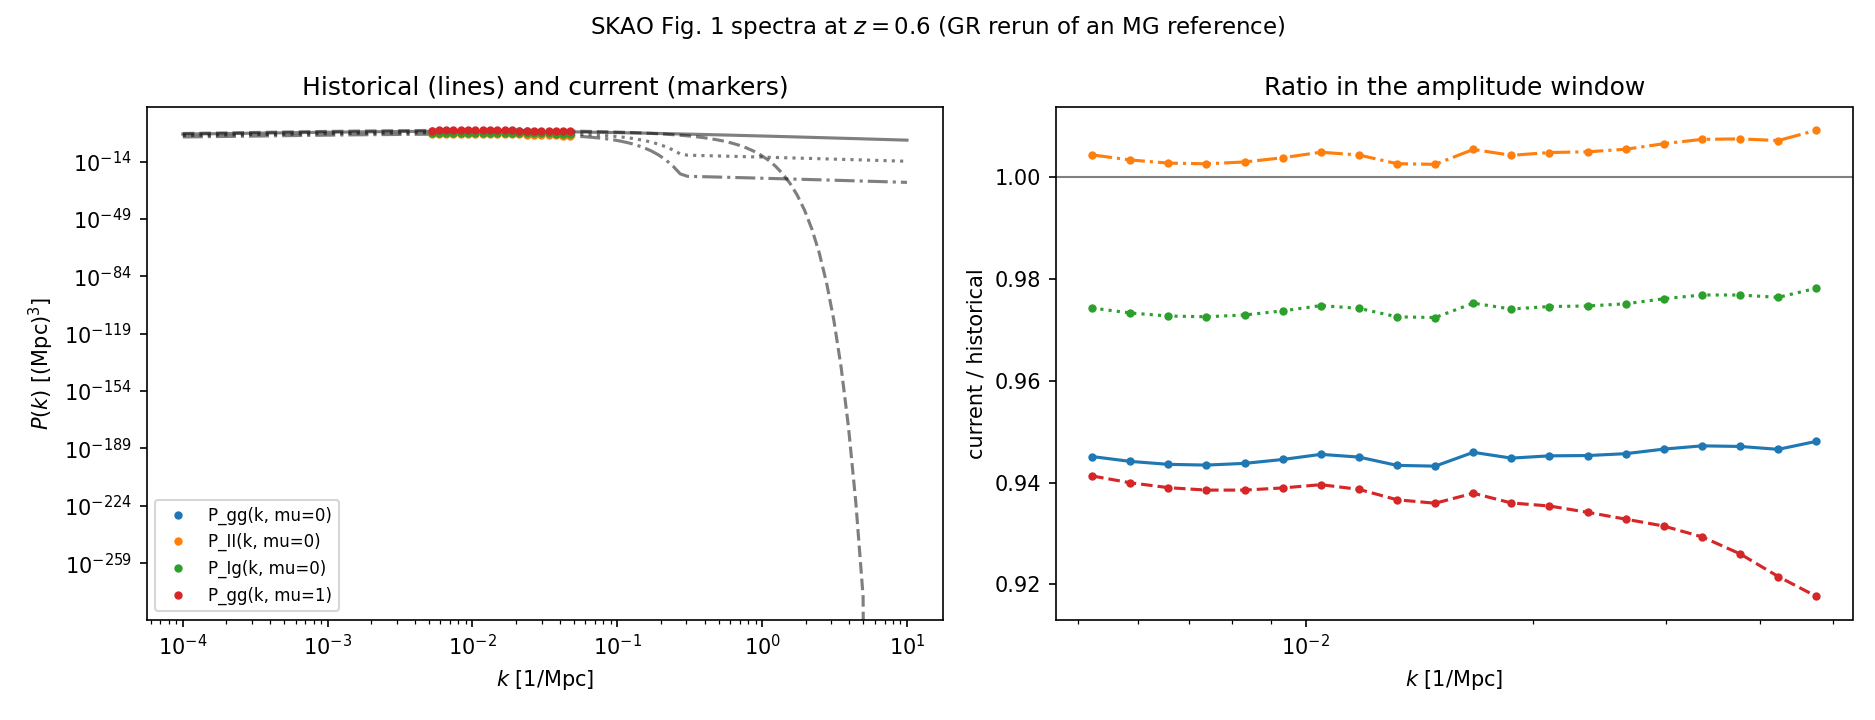

In [7]:
static = REPO_ROOT / "docs/source/_static/survey_validation"
for name in ("forecast_errors.png", "w0wa_comparisons.png", "fig1_diagnostic.png"):
    path = static / name
    if path.exists():
        print(name)
        display(Image(filename=str(path)))
    else:
        print(f"{name} not found; run scripts/validation/plot_survey_validation.py")

## What to take away

* The observable algebra (bin densities, bias, volumes, `P_gg`, IM thermodynamics,
  beam, noise and the photometric `dN/dz` and counts) agrees with the independent
  transcription at machine precision. The photometric angular spectra are not
  re-compared against the historical project here.
* The SKAO Fig. 1 spectra agree in shape to better than 1.5% over the calibrated
  range. Their amplitude offset is consistent with the modified-gravity fiducial used
  in the reference, but the comparison does not isolate that from the other
  differences (backend, table extrapolation, modelling).
* On a common GR fiducial the ranking between surveys is driven by the specification
  (sky area, scale cuts, binning), not by the telescope name. The historical Rubin file
  has wider weak-lensing cuts than the shipped Euclid file, so it looks stronger.
* The IM x DESI-ELG entry is a cross-spectrum-only Fisher, and the Planck-like entry is
  a single-channel approximation run with CAMB. Neither is a substitute for the real
  likelihoods.
* The published SKAO constraints are on modified-gravity parameters and are out of scope
  here; see `docs/SURVEY_VALIDATION_ROADMAP.md` for the full provenance and caveats.
